YOU MUST STILL FILL IN THfE FOLLOWING VARIABLES:
VARIABLES START


varyingVariable,
hasBottail,
obtaining_motor_csv,
numberSims,
processes,
latitude,
longitude,
elevation,
atmosphere_type,
env_file,
fahrenheit_temp,
pressure,
wind_u,
wind_v,
date,
generatedFilesLocation,
dryMotorMass,
propellant_mass,
grainInnerRadius,
grainOuterRadius,
grainHeight,
the_nozzle_radius,
the_throat_radius,
the_nozzle_position,
grain_center_of_mass_position,
center_of_dry_mass_within_motor,
motor_thrust_file,
burn_time,
numGrains,
grainSeparation,
the_motor_position,
the_center_of_mass_without_motor,
rocket_center_of_dry_mass_position,
power_off_file,
power_on_file,
inclination,
heading,
rail_length,
using-airbrakes,


VARIABLES END




C:\Users\mahd\Documents\SimulationRocketPy\rocketpy_repo\rocketpy\mathutils\_calc\polation_1d.py:119: RuntimeWarning: divide by zero encountered in divide
  self._slopes = np.diff(self._y) / np.diff(self._x)
C:\Users\mahd\Documents\SimulationRocketPy\rocketpy_repo\rocketpy\mathutils\_calc\_fitting.py:239: RuntimeWarning: divide by zero encountered in divide
  slopes = np.diff(y) / h
C:\Users\mahd\Documents\SimulationRocketPy\rocketpy_repo\rocketpy\mathutils\_calc\polation_1d.py:219: RuntimeWarning: invalid value encountered in scalar multiply
  + self._slopes[i] * (x - self._x[i]) ** 2 / 2


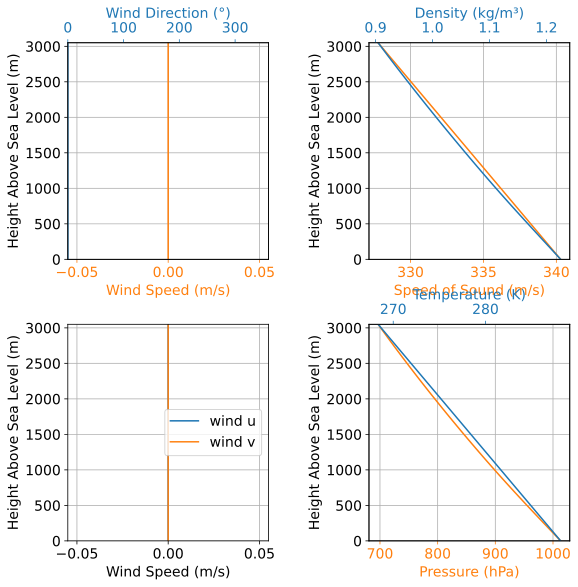

TOTAL SIMS IS: 1


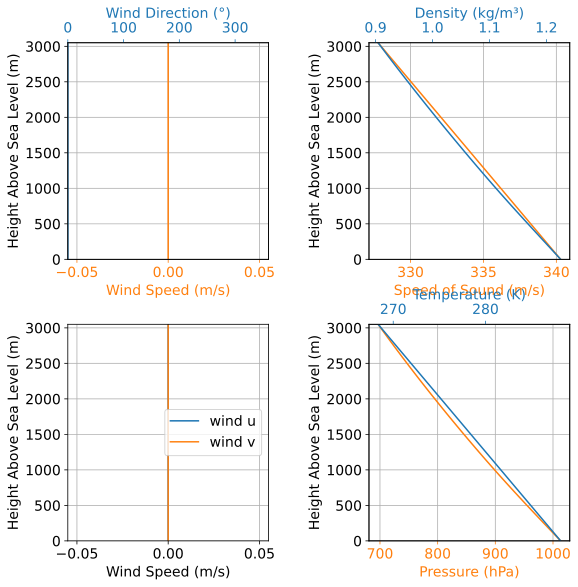

'Completed 1 iterations successfully. Total CPU time: 0.984375 s. Total wall time: 1.0711045265197754 s'

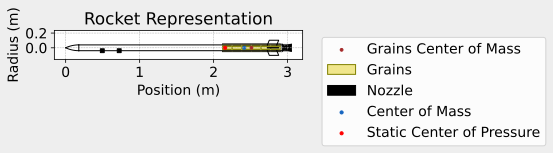

Center of mass without motor is currently set to: 1.58


C:\Users\mahd\Documents\SimulationRocketPy\rocketpy_repo\rocketpy\simulation\flight.py:610: UnstableRocketWarning: The rocket has a negative static margin (-3.28 cal) at motor ignition (t=0), indicating an aerodynamically unstable configuration. Check the placement of fins and nose cone relative to the center of mass.
  self.rocket.warn_if_unstable()


printing ts crack


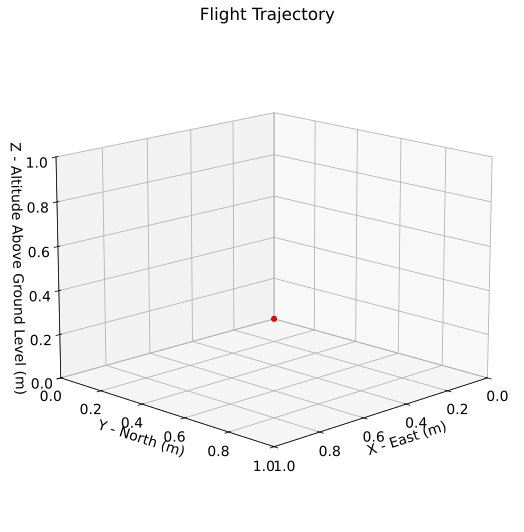


Initial Conditions

Initial time: 0.000 s
Position - x: 0.00 m | y: 0.00 m | z: 750.00 m
Velocity - Vx: 0.00 m/s | Vy: 0.00 m/s | Vz: 0.00 m/s
Attitude (quaternions) - e0: 0.865 | e1: 0.045 | e2: -0.026 | e3: -0.499
Euler Angles - Spin φ : -180.00° | Nutation θ: -6.00° | Precession ψ: 120.00°
Angular Velocity - ω1: 0.00 rad/s | ω2: 0.00 rad/s | ω3: 0.00 rad/s
Initial Stability Margin: -3.284 c


Surface Wind Conditions

Frontal Surface Wind Speed: -0.00 m/s
Lateral Surface Wind Speed: 0.00 m/s


Launch Rail

Launch Rail Length: 7.096 m
Launch Rail Inclination: 84.00°
Launch Rail Heading: 240.00°


Rail Departure State

Rail Departure Time: 0.000 s
Rail Departure Velocity: 0.000 m/s
Rail Departure Stability Margin: -3.284 c
Rail Departure Angle of Attack: 90.000°
Rail Departure Thrust-Weight Ratio: nan
Rail Departure Reynolds Number: 0.000e+00


Burn out State

Burn out time: 3.350 s
Altitude at burn out: 750.000 m (ASL) | 0.000 m (AGL)
Rocket speed at burn out: 0.000 m/s
Freestream ve

FileNotFoundError: [Errno 2] No such file or directory: 'Output/MonteCarlo1.Output.txt'

In [ ]:
from time import process_time, time
from Helpers.ConcurrentFunctions import RunFlightWithMonteCarlo
from IPython.display import display
from scipy.stats import norm
from rocketpy import Environment
import datetime

#Calculate and plot landing elipses
# Import libraries

from Helpers import FlightParams
from Helpers.Wind import MakeWind

%config InlineBackend.figure_formats = ['svg']
import matplotlib as mpl
import matplotlib.pyplot as plt


%matplotlib inline
mpl.rcParams["figure.figsize"] = [8, 5]
mpl.rcParams["figure.dpi"] = 120
mpl.rcParams["font.size"] = 14
mpl.rcParams["legend.fontsize"] = 14
mpl.rcParams["figure.titlesize"] = 14


import logging
import numpy as np

launchDate = [2025, 6, 12, 8]

# Iterate the loop to read the cell values
env = Environment(
    date=launchDate,
    latitude=FlightParams.Parameters["latitude"],
    longitude=FlightParams.Parameters["longitude"],
    max_expected_height=3050
)

env.set_atmospheric_model(type=FlightParams.Parameters["atmosphere_type"], file=FlightParams.Parameters["env_file"])
env.plots.atmospheric_model()

#env = Environment(latitude = FlightParams.envParams["latitude"], longitude = FlightParams.envParams["longitude"], elevation = FlightParams.envParams["elevation"])

analysis_parameters = {
    # Rocket's dry mass without motor (kg) and its uncertainty (standard deviation)
    "rocket_mass": (FlightParams.Parameters["spMass"], 0), #.001
    # # Rocket's inertia moment perpendicular to its axis (kg*m^2)
    "rocket_inertia_11": (FlightParams.Parameters["spCentralDiameter"], 0),
    # # Rocket's inertia moment relative to its axis (kg*m^2)
    "rocket_inertia_33": (FlightParams.Parameters["spCentralAxis"], 0),
    # Motors's dry mass without propellant (kg) and its uncertainty (standard deviation)
    "motor_dry_mass": (FlightParams.Parameters["dryMotorMass"], 0), #.001
    # # Motor's dry inertia moment perpendicular to its axis (kg*m^2)
    "motor_inertia_11": (FlightParams.Parameters["motor_11_inertia"], 0),
    # # Motors's dry inertia moment relative to its axis (kg*m^2)
    "motor_inertia_33": (FlightParams.Parameters["motor_33_inertia"], 0),\
    # Distance between rocket's center of dry mass and motor's center of dry mass (m)
    # THIS is likely wrong, go back to check it

    "motor_dry_mass_position": (np.abs(FlightParams.Parameters["the_motor_center_of_dry_mass_position"] - FlightParams.Parameters["rocket_center_of_dry_mass_position"]), 0), #.001
    # Motor total impulse (N*s)
    "impulse": (FlightParams.Parameters["impulse"], 0), #25.3

    "motor_position": (FlightParams.Parameters["the_motor_position"], 0),

    # Motor burn out time (s)
    "burn_time": (FlightParams.Parameters["burn_time"], 0),
    # Motor's nozzle radius (m)
    "nozzle_radius": (FlightParams.Parameters["the_nozzle_radius"], 0), #.5 / 1000
    # Motor's nozzle throat radius (m)
    "throat_radius": (FlightParams.Parameters["the_throat_radius"], 0), #.5 / 1000
    # Motor's grain separation (axial distance between two grains) (m)
    "grain_separation": (FlightParams.Parameters["grainSeparation"], 0),
    # Motor's grain density (kg/m^3)
    "grain_density": (FlightParams.Parameters["motor_density"], 0), #20
    # Motor's grain outer radius (m)
    "grain_outer_radius": (FlightParams.Parameters["grainOuterRadius"], 0),
    # Motor's grain inner radius (m)
    "grain_initial_inner_radius": (FlightParams.Parameters["grainInnerRadius"], 0), #.3 / 1000
    # Motor's grain height (m)
    "grain_initial_height": (FlightParams.Parameters["grainHeight"], 0), #1 / 1000
    # Rocket's radius (kg*m^2)
    "radius": (FlightParams.Parameters["rocket_radius"], 0),
    # Nozle position relative to motor
    "nozzle_position": (FlightParams.Parameters["the_nozzle_position"], 0),
    # Distance between rocket's center of dry mass and and center of propellant mass (m) (negative)
    "grains_center_of_mass_position": (FlightParams.Parameters["rocket_center_of_dry_mass_position"]-(FlightParams.Parameters["the_motor_center_of_dry_mass_position"] + FlightParams.Parameters["the_motor_position"]), 0), #.0001
    # Axial distance between rocket's center of dry mass and nearest point in its nose cone (m)
    "nose_distance_to_CM": (FlightParams.Parameters["rocket_center_of_dry_mass_position"]-FlightParams.Parameters["nose_cone_length"], 0),
    # Launch rail inclination angle relative to the horizontal plane (degrees)
    "inclination": (FlightParams.Parameters["inclination"], 0), #1
    # Launch rail heading relative to north (degrees)
    "heading": (FlightParams.Parameters["heading"], 0), #2

    # # Drag coefficient times reference area for the drogue chute (m^2)
    # "cd_s_drogue": (FlightParams.Parameters["drogueCdS"], 0), #.02
    # # Drag coefficient times reference area for the light chute
    # "cd_s_light": (FlightParams.Parameters["lightCdS"], 0), #.02
    # # Time delay between parachute ejection signal is detected and parachute is inflated (s)
    # "lag_rec": (FlightParams.Parameters["lag_rec"], 0), #.2
    # # Time delay between sensor signal is received and ejection signal is fired (s)
    # "lag_se": (FlightParams.Parameters["lag_se"], 0), #.1

    # temperature in kelvin
    "temperature": (FlightParams.Parameters["temperature"], 0), #5
    # atmospheric pressure in pascals
    "atmosphere_pressure": (env.pressure_ISA(FlightParams.Parameters["elevation"]), 0), #300

    #without motor
    "rocket_CM": (FlightParams.Parameters["rocket_center_of_dry_mass_position"], 0), #.01

    # adding these, but they don't vary
    "time_to_deploy_airbrake_after_burnout": (0.1, 0),
    "fin_position": (2.62, 0)
}

# M1850W.all_info()

#sets up the ability to log inputs.
def setup_logging():
    class MyHandler(logging.FileHandler):
        def emit(self, record):
            super().emit(record)  # Call the superclass's emit method
            self.flush()  # Flush after each log message

    # Use your custom handler
    logger = logging.getLogger()
    logger.setLevel(logging.INFO)
    handler = MyHandler('app.log', 'a')
    formatter = logging.Formatter('%(asctime)s - %(levelname)s - %(message)s')
    handler.setFormatter(formatter)
    logger.addHandler(handler)

resultsFile = open(FlightParams.Parameters["generatedFilesLocation"] + "results.txt", "w")

def createDistributionPlot(dispersonResultArray, name, lowerProbBound, upperProbBound, maxDecimals, percentConfidence, hypothesis, unit, makeGraph, filename):
    mean = np.mean(dispersonResultArray)
    deviation = np.std(dispersonResultArray)
    unitString = ""
    if(unit == "meters"):
        unitString = "m"
    print(
        f'{name} -         Mean Value: {mean:0.3f} ' + unitString
    )
    resultsFile.write(f'{name} -         Mean Value: {mean:0.3f} ' + unitString + "\n")
    print(
        f'{name} - Standard Deviation: {deviation:0.3f} m' + unitString
    )
    resultsFile.write(f'{name} - Standard Deviation: {deviation:0.3f} m' + unitString + "\n")
    if(makeGraph):

        print(f"Arr: {dispersonResultArray}")
        minimum = np.min(dispersonResultArray)
        maximum = np.max(dispersonResultArray)
        theBins = list()

        #using scott's rule to find the number of bins
        binWidth = 3.5 * deviation / np.power(len(dispersonResultArray), 1/3)
        numBins = int(np.round((maximum-minimum)/binWidth))

        changeInZ = (maximum - minimum) / numBins
        #test add
        zIterator = minimum
        for iterator in range(numBins):
            theBins.append(zIterator)
            zIterator += changeInZ
        finalValue = np.ceil(zIterator * np.power(10, maxDecimals)) / np.power(10, maxDecimals)
        theBins.append(finalValue)
        plt.figure()
        plt.xlim(minimum, maximum)
        minTextSize = 8
        maxTickCount = 50
        xTickBins = theBins
        if(numBins > maxTickCount):
            xTickBins = list()
            changeInZ = (maximum - minimum) / 50.0
            zIterator = minimum
            for iterator in range(50):
                xTickBins.append(zIterator)
                zIterator += changeInZ
        binListToString = list()
        for currentBin in xTickBins:
            binListToString.append(str(round(currentBin, maxDecimals)))
        plt.xticks(ticks = xTickBins, labels = binListToString, rotation = 75, fontsize = minTextSize)
        plt.hist(dispersonResultArray, bins=theBins)
        plt.title(name)
        plt.xlabel(name)
        plt.ylabel("Number of Occurences")

        plt.axvline(mean, color='k', linestyle='solid', linewidth=4)
        plt.axvline(mean - deviation, color='g', linestyle='solid', linewidth=3)
        plt.axvline(mean - 2*deviation, color='g', linestyle='solid', linewidth=3)
        plt.axvline(mean - 3*deviation, color='g', linestyle='solid', linewidth=3)
        plt.axvline(mean + deviation, color='g', linestyle='solid', linewidth=3)
        plt.axvline(mean + 2*deviation, color='g', linestyle='solid', linewidth=3)
        plt.axvline(mean + 3*deviation, color='g', linestyle='solid', linewidth=3)
        plt.savefig(FlightParams.generatedFilesLocation + str(filename) + "Graph.png", bbox_inches="tight", pad_inches=0)
        plt.show()
    lowerZ = (lowerProbBound - mean)/deviation
    upperZ = (upperProbBound - mean)/deviation
    probabilityInRange = norm.cdf(upperZ) - norm.cdf(lowerZ)
    print("PROBABILITY THE " + name +  " IS IN BETWEEN " + str(round(lowerProbBound, 4)) + " AND " + str(round(upperProbBound, 4)) + " IS: " + str(round(probabilityInRange * 100, 2)) + "%")
    resultsFile.write("PROBABILITY THE " + name +  " IS IN BETWEEN " + str(round(lowerProbBound, 4)) + " AND " + str(round(upperProbBound, 4)) + " IS: " + str(round(probabilityInRange * 100, 2)) + "%\n")
    if(percentConfidence != 100):
        aVal = (100 - percentConfidence)/100
        newZ = np.abs(norm.ppf(aVal/2))
        lowerBoundOfInterval = mean - newZ * deviation/np.sqrt(len(dispersonResultArray))
        upperBoundOfInterval = mean + newZ * deviation/np.sqrt(len(dispersonResultArray))
        print("There is a " + str(percentConfidence) + f"% chance that the mean of the " + name + 
              " falls within THIS RANGE: " + str(lowerBoundOfInterval) + ", " + str(upperBoundOfInterval))
        resultsFile.write("There is a " + str(percentConfidence) + f"% chance that the mean of the " + name + 
              " falls within THIS RANGE: " + str(lowerBoundOfInterval) + ", " + str(upperBoundOfInterval) + "\n")
        if(hypothesis != None):
            criticalValue = norm.ppf(aVal / 2)
            testStatistic = (mean - hypothesis) * np.sqrt(len(dispersonResultArray))/deviation
            print("\nWe have the hypothesis that our mean is greater than or equal to " + str(hypothesis) + ". With our critical percent, our critical value is " +
                str(criticalValue) + ". Then, our test statistic is " + str(testStatistic))
            resultsFile.write("\nWe have the hypothesis that our mean is greater than or equal to " + str(hypothesis) + ". With our critical percent, our critical value is " +
                str(criticalValue) + ". Then, our test statistic is " + str(testStatistic) + "\n")
            if(testStatistic < criticalValue):
                print("Since our test statistic is more extreme than our critical value, we can reject the null hypothesis that the mean is " + str(hypothesis) + ".\n")
                resultsFile.write("Since our test statistic is more extreme than our critical value, we can reject the null hypothesis that the mean is " + str(hypothesis) + ".\n\n")
            else:
                print("Since our test statistic is less extreme than our critical value, we can NOT reject the null hypothesis that the mean is " + str(hypothesis) + ".\n")
                resultsFile.write("Since our test statistic is less extreme than our critical value, we can NOT reject the null hypothesis that the mean is " + str(hypothesis) + ".\n\n")

# envParams["env_file"] = row[0].value

print("TOTAL SIMS IS: " + str(FlightParams.Parameters["numberSims"]))
resultsFile.write("TOTAL SIMS IS: " + str(FlightParams.Parameters["numberSims"]) + "\n\n\n")
    
env.set_atmospheric_model(type=FlightParams.Parameters["atmosphere_type"])
env.plots.atmospheric_model()

setup_logging()
# env.all_info()
# Create data files for inputs, outputs and error logging
filename = "MonteCarlo1"
MonteCarloErrorFile = open("../Output/" + str(filename) + ".Errors.txt", "w")
MonteCarloInputFile = open("../Output/" + str(filename) + ".Input.txt", "w")
MonteCarloOutputFile = open("../Output/" + str(filename) + ".Output.txt", "w")

initial_wall_time = time()
initial_cpu_time = process_time()
# Iterate over flight settings
out = display("Starting", display_id=True)
number_of_simulations = FlightParams.Parameters["numberSims"]
totalProcesses = FlightParams.Parameters["processes"]
simsPerProcess = number_of_simulations / totalProcesses

# runFlightWithMonteCarlo(simsPerProcess, FlightParams.envParams, analysis_parameters, initial_cpu_time, False, theLaunchDate)

theDate = datetime.date.today()
theDate = [theDate.year, theDate.month, theDate.day, 12]

RunFlightWithMonteCarlo(1, analysis_parameters, initial_cpu_time, False, theDate)


## Print and save total time
final_string = f"Completed {number_of_simulations} iterations successfully. Total CPU time: {process_time() - initial_cpu_time} s. Total wall time: {time() - initial_wall_time} s"
resultsFile.write(f"Completed {number_of_simulations} iterations successfully. Total CPU time: {process_time() - initial_cpu_time} s. Total wall time: {time() - initial_wall_time} s\n")
out.update(final_string)
MonteCarloInputFile.write(final_string + "\n")
MonteCarloOutputFile.write(final_string + "\n")
MonteCarloErrorFile.write(final_string + "\n")

## Close files
MonteCarloInputFile.close()
MonteCarloOutputFile.close()
MonteCarloErrorFile.close()

# Initialize variable to store all results
dispersion_general_results = []

dispersion_results = {
    "out_of_rail_time": [],
    "out_of_rail_velocity": [],
    "apogee_time": [],
    "apogee_altitude": [],
    "apogee_x": [],
    "apogee_y": [],
    "impact_x": [],
    "impact_y": [],
    "initial_static_margin": [],
    "out_of_rail_static_margin": [],
    "out_of_rail_stability_margin": [],
    "max_velocity": [],
    "execution_time": [],
}

# Get all dispersion results
# Get file
dispersion_output_file = open("../Output/" + str(filename) + ".Output.txt", "r+")

# Read each line of the file and convert to dict
for line in dispersion_output_file:
    # Skip comments lines
    if line[0] != "{":
        continue
    # Eval results and store them
    flight_result = eval(line)
    dispersion_general_results.append(flight_result)
    for parameter_key, parameter_value in flight_result.items():
        dispersion_results[parameter_key].append(parameter_value)

# Close data file
dispersion_output_file.close()

# Print number of flights simulated
N = len(dispersion_general_results)
print("Number of simulations: ", N)
resultsFile.write("Number of simulations: " + str(N) + "\n")

# Retrieve dispersion data por apogee and impact XY position
apogee_x = np.array(dispersion_results["apogee_x"])
apogee_y = np.array(dispersion_results["apogee_y"])

resultsFile.close()